# Remove Timestamp Rectangles from Images

## Mục tiêu
Cắt bỏ vùng hình chữ nhật xám đen ở trên cùng bên trái của 5 class:
- Pinus krempfii
- Calocedrus rupestris
- Picea glauca
- Taxus wallichiana
- Xanthocyparis vietnamensis

## Quy trình
1. Cell 1: Setup & Check data
2. Cell 2: Explore 5 samples from each class
3. Cell 3: Test crop with 10 images
4. Cell 4: Process all images in 5 classes

---
## Cell 1: Setup & Check Data Exists

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm
import shutil

current = Path.cwd().resolve()
ROOT = next(
    (path for path in (current, *current.parents)
        if (path / 'data-taskB/check-data/show_review_images.py').is_file()),
    current,
)

# Dataset path
DATA_DIR = ROOT/ "data" / "task-B-group-split"

# 5 classes có timestamp cần xử lý
TARGET_CLASSES = [
    'Pinus krempfii',
    'Calocedrus rupestris',
    'Picea glauca',
    'Taxus wallichiana',
    'Xanthocyparis vietnamensis'
]

print("=" * 80)
print("REMOVE TIMESTAMP RECTANGLES - SETUP")
print("=" * 80)
print(f"Dataset path: {DATA_DIR}")
print(f"Dataset exists: {DATA_DIR.exists()}")
print()

# Check từng class
print("Checking target classes:")
class_stats = {}

for split in ['train', 'val', 'test']:
    split_dir = DATA_DIR / split
    if not split_dir.exists():
        print(f"  ❌ {split} directory not found!")
        continue
    
    for class_name in TARGET_CLASSES:
        class_dir = split_dir / class_name
        if class_dir.exists():
            image_files = [f for f in class_dir.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
            count = len(image_files)
            
            key = f"{split}/{class_name}"
            class_stats[key] = count
            
            print(f"  ✅ {split}/{class_name}: {count} images")
        else:
            print(f"  ❌ {split}/{class_name}: NOT FOUND")

print()
total_images = sum(class_stats.values())
print(f"📊 Total images to process: {total_images:,}")
print("=" * 80)

REMOVE TIMESTAMP RECTANGLES - SETUP
Dataset path: /home/sakana/Code/ManifoldsTeam/woodbench/data/task-B-group-split
Dataset exists: True

Checking target classes:
  ✅ train/Pinus krempfii: 222 images
  ✅ train/Calocedrus rupestris: 191 images
  ✅ train/Picea glauca: 199 images
  ✅ train/Taxus wallichiana: 157 images
  ✅ train/Xanthocyparis vietnamensis: 192 images
  ✅ val/Pinus krempfii: 46 images
  ✅ val/Calocedrus rupestris: 57 images
  ✅ val/Picea glauca: 54 images
  ✅ val/Taxus wallichiana: 40 images
  ✅ val/Xanthocyparis vietnamensis: 60 images
  ✅ test/Pinus krempfii: 36 images
  ✅ test/Calocedrus rupestris: 24 images
  ✅ test/Picea glauca: 25 images
  ✅ test/Taxus wallichiana: 26 images
  ✅ test/Xanthocyparis vietnamensis: 32 images

📊 Total images to process: 1,361


---
## Cell 2: Explore 5 Samples from Each Class (All Splits)

COLLECTING SAMPLE IMAGES
Total samples collected: 75



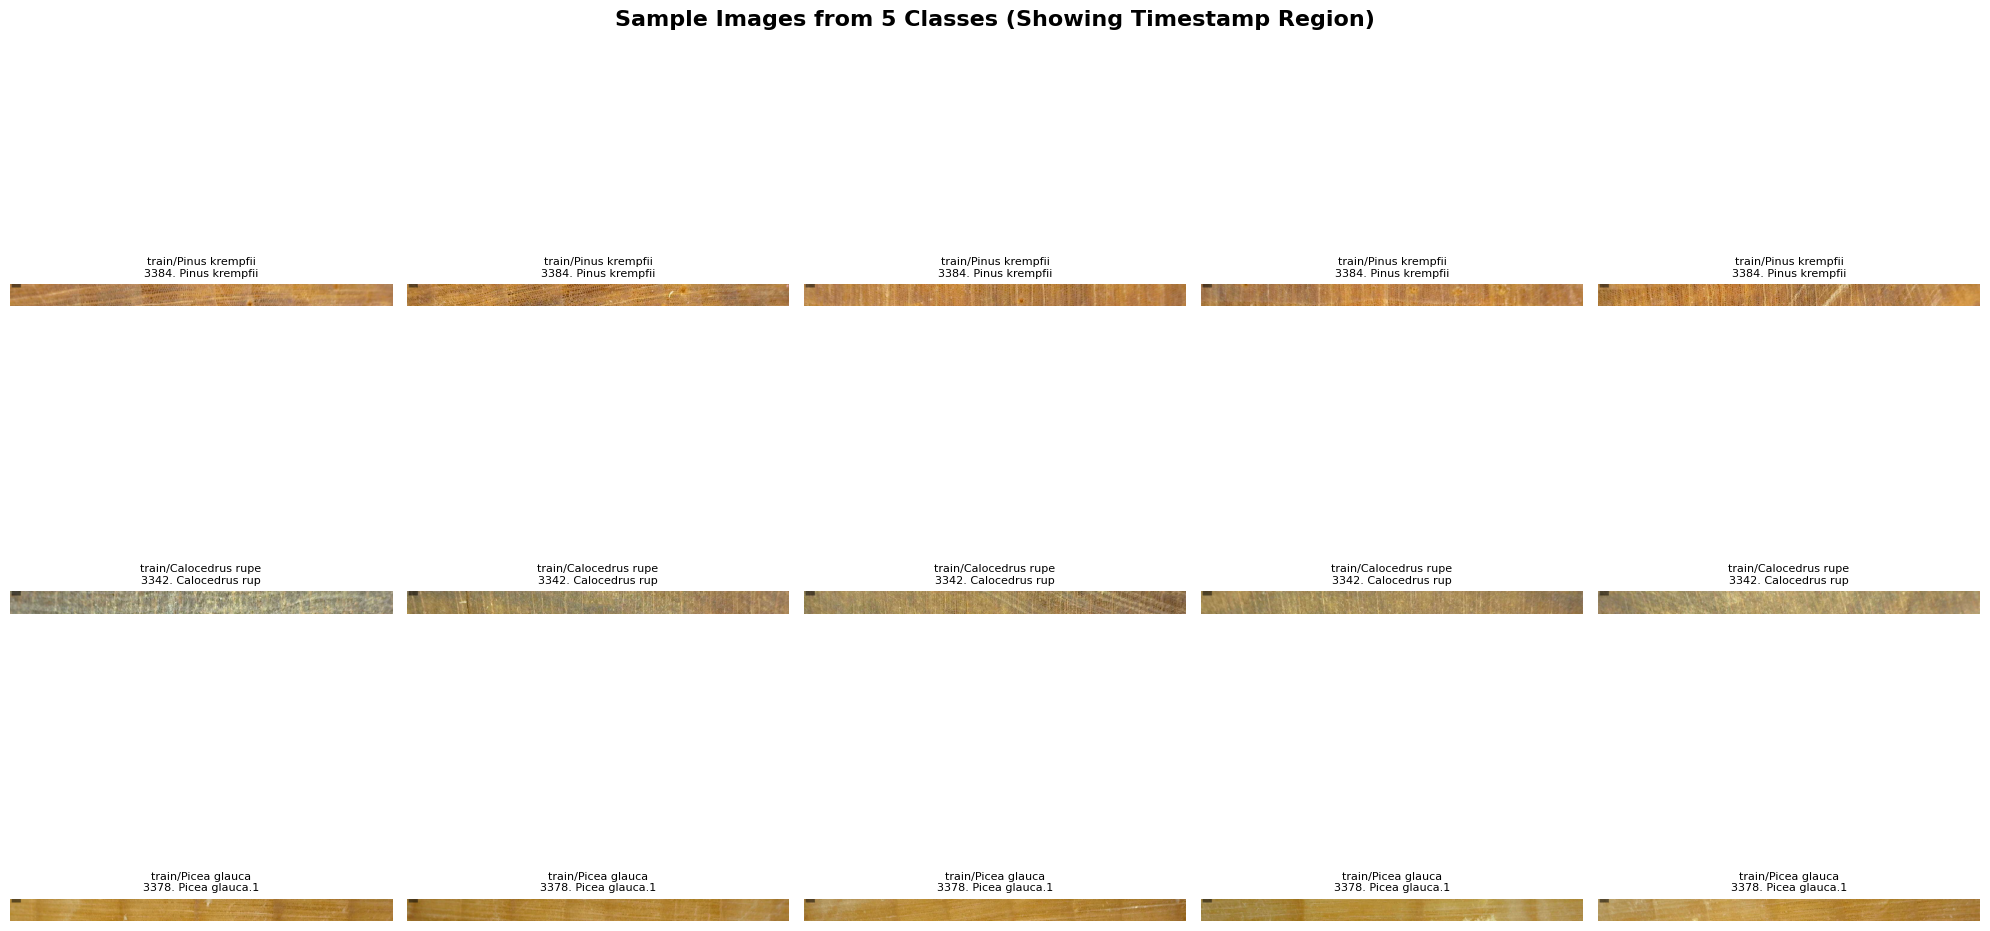


📸 Displayed 15 sample images (top 150px region)
Observe the gray/dark timestamp rectangle at top-left corner


In [2]:
# Collect 5 samples from each class in each split
print("=" * 80)
print("COLLECTING SAMPLE IMAGES")
print("=" * 80)

sample_images = []

for split in ['train', 'val', 'test']:
    split_dir = DATA_DIR / split
    if not split_dir.exists():
        continue
    
    for class_name in TARGET_CLASSES:
        class_dir = split_dir / class_name
        if not class_dir.exists():
            continue
        
        # Get first 5 images
        image_files = sorted([f for f in class_dir.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']])[:5]
        
        for img_file in image_files:
            sample_images.append({
                'path': img_file,
                'split': split,
                'class': class_name,
                'filename': img_file.name
            })

print(f"Total samples collected: {len(sample_images)}")
print()

# Visualize first 15 samples
num_display = min(15, len(sample_images))
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
fig.suptitle('Sample Images from 5 Classes (Showing Timestamp Region)', fontsize=16, fontweight='bold')
axes = axes.flatten()

for i, sample in enumerate(sample_images[:num_display]):
    img = cv2.imread(str(sample['path']))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Show top 150 pixels để thấy rõ timestamp
    img_top = img_rgb[:150, :, :]
    
    axes[i].imshow(img_top)
    axes[i].set_title(f"{sample['split']}/{sample['class'][:15]}\n{sample['filename'][:20]}", fontsize=8)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

print(f"\n📸 Displayed {num_display} sample images (top 150px region)")
print("Observe the gray/dark timestamp rectangle at top-left corner")

---
## Cell 3: Test Crop with 10 Images & Show Results

TEST CROP WITH 10 IMAGES
✅ 3384. Pinus krempfii (35).png            -> Crop 35px
✅ 3384. Pinus krempfii (36).png            -> Crop 36px
✅ 3384. Pinus krempfii (37).png            -> Crop 35px
✅ 3384. Pinus krempfii (38).png            -> Crop 36px
✅ 3384. Pinus krempfii (39).png            -> Crop 36px
✅ 3342. Calocedrus rupestris.1.(1).png     -> Crop 37px
✅ 3342. Calocedrus rupestris.1.(10).png    -> Crop 36px
✅ 3342. Calocedrus rupestris.1.(11).png    -> Crop 36px
✅ 3342. Calocedrus rupestris.1.(12).png    -> Crop 35px
✅ 3342. Calocedrus rupestris.1.(13).png    -> Crop 36px

Successfully cropped: 10 / 10 images


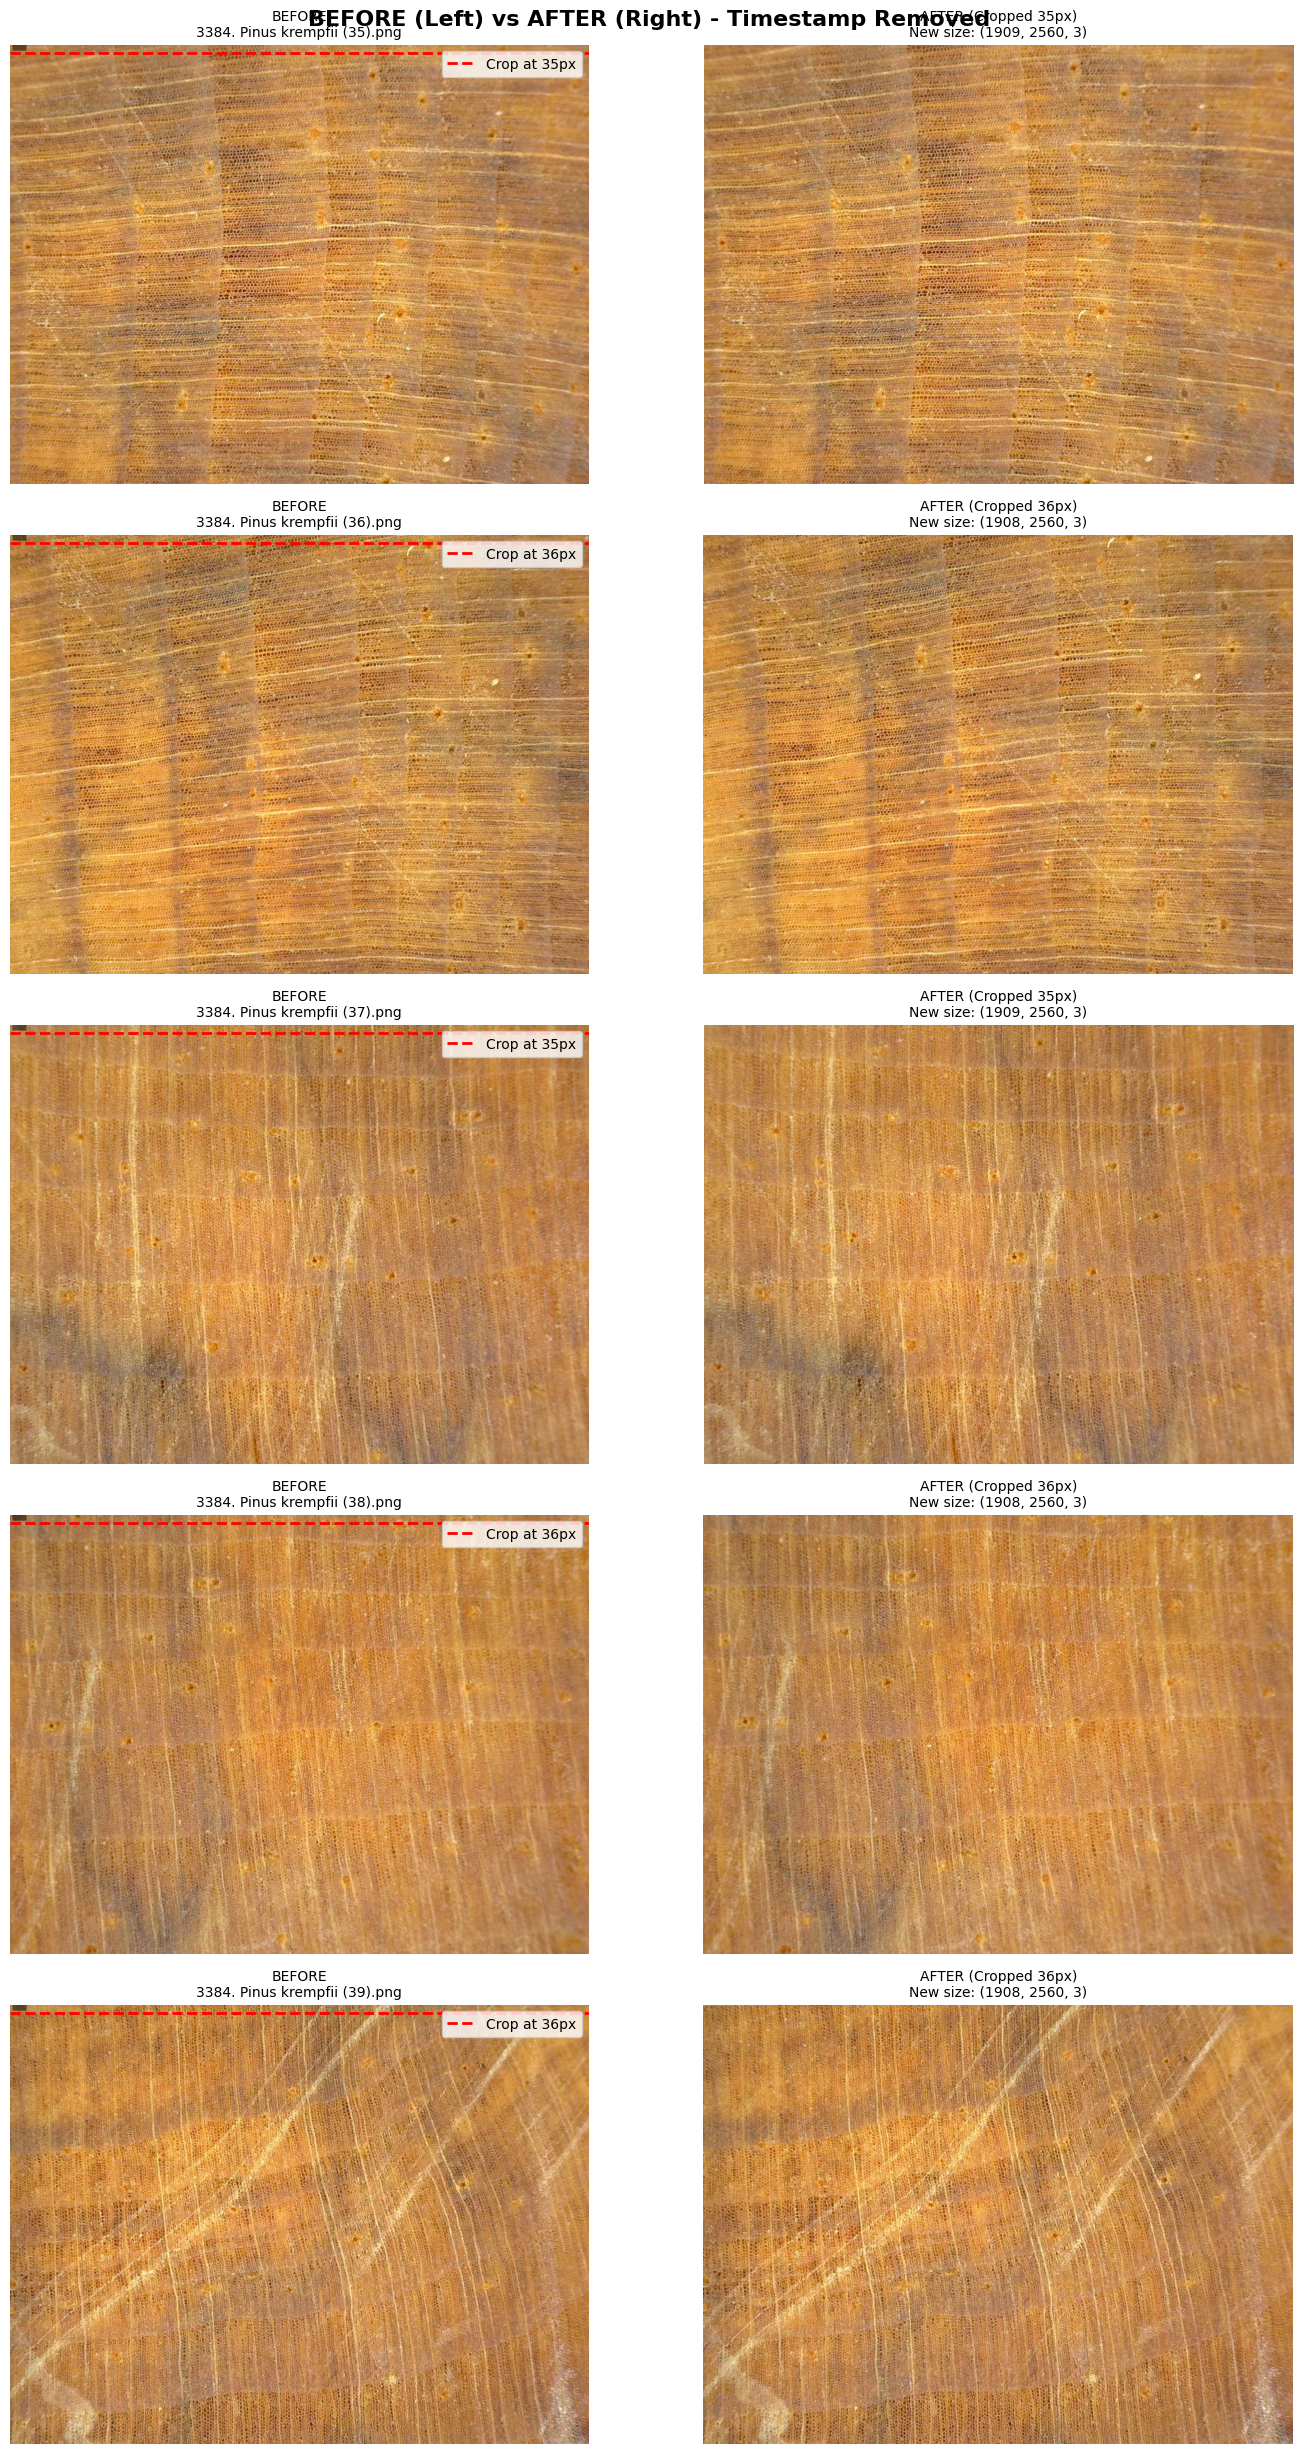


📸 Displayed 5 examples of cropped images
✅ Red line shows where the crop was applied


In [3]:
def detect_timestamp_height(image_path):
    """
    Detect chiều cao của timestamp rectangle.
    Trả về số pixels cần cắt từ trên xuống.
    """
    try:
        img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if img is None:
            return 0
        
        height, width = img.shape
        
        # Check vùng top-left 250x150
        corner_width = min(250, width // 2)
        corner_height = min(150, height // 3)
        corner_region = img[:corner_height, :corner_width]
        
        # Adaptive threshold
        mean_corner = np.mean(corner_region)
        adaptive_threshold = mean_corner - 20
        
        dark_mask = corner_region < adaptive_threshold
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
        dark_mask_clean = cv2.morphologyEx(dark_mask.astype(np.uint8) * 255, 
                                          cv2.MORPH_CLOSE, kernel)
        
        contours, _ = cv2.findContours(dark_mask_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        # Tìm contour gần góc (0,0) nhất
        best_crop_height = 0
        
        for contour in contours:
            area = cv2.contourArea(contour)
            if area < 300:
                continue
            
            x, y, w, h = cv2.boundingRect(contour)
            
            # Phải gần góc (0,0)
            if x > 30 or y > 20:
                continue
            
            # Phải là chữ nhật ngang
            aspect_ratio = w / h if h > 0 else 0
            if aspect_ratio < 1.5 or w < 50 or h < 10:
                continue
            
            # Chiều cao cần crop = y + h + margin
            crop_height = y + h + 5  # Thêm 5px margin
            best_crop_height = max(best_crop_height, crop_height)
        
        return best_crop_height
        
    except Exception as e:
        print(f"Error detecting: {e}")
        return 0


def crop_image(image_path, crop_height):
    """
    Cắt ảnh: loại bỏ crop_height pixels từ trên xuống.
    Trả về ảnh đã cắt.
    """
    img = cv2.imread(str(image_path))
    if img is None:
        return None
    
    # Crop từ crop_height trở xuống
    cropped = img[crop_height:, :, :]
    return cropped


# TEST với 10 ảnh đầu tiên
print("=" * 80)
print("TEST CROP WITH 10 IMAGES")
print("=" * 80)

test_samples = sample_images[:10]
test_results = []

for sample in test_samples:
    crop_height = detect_timestamp_height(sample['path'])
    
    if crop_height > 0:
        cropped_img = crop_image(sample['path'], crop_height)
        test_results.append({
            'sample': sample,
            'crop_height': crop_height,
            'cropped_img': cropped_img,
            'success': cropped_img is not None
        })
        print(f"✅ {sample['filename'][:40]:<40} -> Crop {crop_height}px")
    else:
        print(f"⚠️  {sample['filename'][:40]:<40} -> No timestamp detected")

print(f"\nSuccessfully cropped: {len(test_results)} / {len(test_samples)} images")

# Visualize BEFORE vs AFTER
if test_results:
    num_show = min(5, len(test_results))
    fig, axes = plt.subplots(num_show, 2, figsize=(15, 5 * num_show))
    if num_show == 1:
        axes = axes.reshape(1, -1)
    
    fig.suptitle('BEFORE (Left) vs AFTER (Right) - Timestamp Removed', fontsize=16, fontweight='bold')
    
    for i, result in enumerate(test_results[:num_show]):
        # BEFORE
        img_before = cv2.imread(str(result['sample']['path']))
        img_before_rgb = cv2.cvtColor(img_before, cv2.COLOR_BGR2RGB)
        axes[i, 0].imshow(img_before_rgb)
        axes[i, 0].set_title(f"BEFORE\n{result['sample']['filename'][:30]}", fontsize=10)
        axes[i, 0].axis('off')
        
        # Draw crop line
        axes[i, 0].axhline(y=result['crop_height'], color='red', linestyle='--', linewidth=2, label=f"Crop at {result['crop_height']}px")
        axes[i, 0].legend(loc='upper right')
        
        # AFTER
        img_after_rgb = cv2.cvtColor(result['cropped_img'], cv2.COLOR_BGR2RGB)
        axes[i, 1].imshow(img_after_rgb)
        axes[i, 1].set_title(f"AFTER (Cropped {result['crop_height']}px)\nNew size: {img_after_rgb.shape}", fontsize=10)
        axes[i, 1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n📸 Displayed {num_show} examples of cropped images")
    print("✅ Red line shows where the crop was applied")

---
## Cell 4: Process ALL Images in 5 Classes & Save

In [5]:
# BACKUP trước khi xử lý
print("=" * 80)
print("⚠️  WARNING: THIS WILL REPLACE ORIGINAL IMAGES!")
print("=" * 80)
print("\nBefore proceeding, make sure you have a BACKUP of your dataset.")
print("This operation will OVERWRITE original images with cropped versions.")
print()

# Uncomment dòng dưới để chạy
CONFIRM_PROCESS = input("Type 'YES' to proceed: ")

if CONFIRM_PROCESS != 'YES':
    print("\n❌ Process cancelled. Type 'YES' to confirm.")
else:
    print("\n✅ Confirmed. Starting to process ALL images...")
    print("=" * 80)
    
    # Collect ALL images from 5 target classes
    all_images_to_process = []
    
    for split in ['train', 'val', 'test']:
        split_dir = DATA_DIR / split
        if not split_dir.exists():
            continue
        
        for class_name in TARGET_CLASSES:
            class_dir = split_dir / class_name
            if not class_dir.exists():
                continue
            
            image_files = [f for f in class_dir.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
            all_images_to_process.extend(image_files)
    
    print(f"📊 Total images to process: {len(all_images_to_process):,}")
    print()
    
    # Process statistics
    stats = {
        'total': len(all_images_to_process),
        'processed': 0,
        'skipped': 0,
        'errors': 0,
        'crop_heights': []
    }
    
    # Process each image
    for img_path in tqdm(all_images_to_process, desc="Processing images"):
        try:
            # Detect crop height
            crop_height = detect_timestamp_height(img_path)
            
            if crop_height == 0:
                stats['skipped'] += 1
                continue
            
            # Crop image
            cropped_img = crop_image(img_path, crop_height)
            
            if cropped_img is None:
                stats['errors'] += 1
                continue
            
            # Save (OVERWRITE original)
            cv2.imwrite(str(img_path), cropped_img)
            
            stats['processed'] += 1
            stats['crop_heights'].append(crop_height)
            
        except Exception as e:
            stats['errors'] += 1
            print(f"\nError processing {img_path.name}: {e}")
    
    # Print results
    print("\n" + "=" * 80)
    print("✅ PROCESSING COMPLETE!")
    print("=" * 80)
    print(f"📊 STATISTICS:")
    print(f"   Total images: {stats['total']:,}")
    print(f"   ✅ Successfully processed: {stats['processed']:,}")
    print(f"   ⚠️  Skipped (no timestamp): {stats['skipped']:,}")
    print(f"   ❌ Errors: {stats['errors']:,}")
    
    if stats['crop_heights']:
        avg_crop = np.mean(stats['crop_heights'])
        min_crop = np.min(stats['crop_heights'])
        max_crop = np.max(stats['crop_heights'])
        print()
        print(f"📏 CROP STATISTICS:")
        print(f"   Average crop height: {avg_crop:.1f}px")
        print(f"   Min crop height: {min_crop}px")
        print(f"   Max crop height: {max_crop}px")
    
    print("\n" + "=" * 80)
    print("🎉 ALL IMAGES HAVE BEEN UPDATED!")
    print("   Original images were REPLACED with cropped versions.")
    print("   Timestamp rectangles have been removed from 5 target classes.")
    print("=" * 80)

⚠️  WARNING: THIS WILL REPLACE ORIGINAL IMAGES!

Before proceeding, make sure you have a BACKUP of your dataset.
This operation will OVERWRITE original images with cropped versions.


✅ Confirmed. Starting to process ALL images...
📊 Total images to process: 1,361



Processing images: 100%|██████████| 1361/1361 [05:51<00:00,  3.87it/s]


✅ PROCESSING COMPLETE!
📊 STATISTICS:
   Total images: 1,361
   ✅ Successfully processed: 1,312
   ⚠️  Skipped (no timestamp): 49
   ❌ Errors: 0

📏 CROP STATISTICS:
   Average crop height: 36.7px
   Min crop height: 15px
   Max crop height: 133px

🎉 ALL IMAGES HAVE BEEN UPDATED!
   Original images were REPLACED with cropped versions.
   Timestamp rectangles have been removed from 5 target classes.
